<a href="https://colab.research.google.com/github/jaiswalvik/MathematicalFoundationsOfGenerativeAI/blob/master/Image_Classification_ResNet_VGG19_dataset1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Classification with Pretrained CNNs
## ResNet-18, ResNet-34 and VGG-19

This Google Colab notebook is adapted for the folder structure shown in your screenshots:

```text
dataset1/
├── train/
│   ├── n01820546/
│   │   ├── image_1.jpg
│   │   └── ...
│   ├── n01833805/
│   └── ... (class folders)
└── test/
    ├── n01820546/
    ├── n01833805/
    └── ... (matching class folders)
```

**Important:** Each class folder name is treated as its label by `torchvision.datasets.ImageFolder`. CSV files are not required.

### Workflow
1. Set up Colab and find the dataset.
2. Load images and create a stratified train/validation split.
3. Apply ImageNet preprocessing and training augmentation.
4. Fine-tune pretrained ResNet-18, ResNet-34 and VGG-19.
5. Evaluate validation and test accuracy.
6. Save checkpoints, prediction CSVs, learning curves and a results summary.

Run the cells from top to bottom. A GPU is recommended: **Runtime → Change runtime type → T4 GPU**.

## 1. Install dependencies

Colab usually includes PyTorch and torchvision already. This cell installs the remaining packages and ensures the core packages are available.

In [1]:
%pip -q install torch torchvision scikit-learn matplotlib pandas pillow

## 2. Connect to Google Drive

Put your `dataset1` folder in Google Drive, for example at `MyDrive/dataset1/`, or upload a ZIP containing the `dataset1/` folder.

Choose one method:
- **Recommended:** store the extracted `dataset1` folder in Drive and set `DATA_DIR` in the next section.
- Alternatively, upload a ZIP and extract it in Colab.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import zipfile

# Update this path to match your Google Drive.
ZIP_PATH = "/content/drive/MyDrive/dataset1.zip"

# Extract the dataset into Colab's temporary storage.
EXTRACT_DIR = "/content"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    zip_file.extractall(EXTRACT_DIR)

print("Dataset extracted to:", EXTRACT_DIR)
print("Extracted items:", os.listdir(EXTRACT_DIR))

# Optional: upload a ZIP from your computer instead of using Google Drive.
# Uncomment and run this cell only if you want to upload a ZIP file.
#
# from google.colab import files
# uploaded = files.upload()
# zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
# if zip_name is None:
#     raise ValueError("Please upload a .zip file containing dataset1/train and dataset1/test.")
# extract_to = Path("/content/dataset_extracted")
# extract_to.mkdir(parents=True, exist_ok=True)
# with zipfile.ZipFile(zip_name, "r") as archive:
#     archive.extractall(extract_to)
# print("Extracted to:", extract_to)
# print("Top-level contents:", [p.name for p in extract_to.iterdir()])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted to: /content
Extracted items: ['.config', '__MACOSX', 'drive', 'dataset1', 'sample_data']


## 3. Configure paths and experiment settings

**Change `DATA_DIR` if your folder is stored somewhere else.** It must point to the directory that directly contains `train/` and `test/`.

Example Drive path: `/content/drive/MyDrive/dataset1`

In [3]:
from pathlib import Path
import os
import random
import copy
import json
import time

# EDIT THIS PATH to the dataset1 directory containing train/ and test/.
DATA_DIR = Path("/content/dataset1")

# All models, plots, CSV predictions and summary files will be saved here.
OUTPUT_DIR = Path("/content/drive/MyDrive/dataset1_outputs")

# Experiment settings. Reduce EPOCHS for a quick test run.
MODEL_NAMES = ("resnet18", "resnet34", "vgg19")
EPOCHS = 10
BATCH_SIZE = 16
LEARNING_RATE = 1e-4
IMAGE_SIZE = 224
NUM_WORKERS = 2
SEED = 42
PRETRAINED = True
VALIDATION_FRACTION = 0.20

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Fix random seeds to make the split and initialization more reproducible.
random.seed(SEED)
torch_seed_placeholder = SEED  # PyTorch is imported in the next section.

print("Dataset directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Dataset directory: /content/dataset1
Output directory: /content/drive/MyDrive/dataset1_outputs


## 4. Import libraries and select the device

The notebook uses PyTorch for training, torchvision for pretrained CNNs and image transforms, scikit-learn for a stratified split, and pandas for exporting predictions.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

def set_seed(seed=42):
    # Seed Python and PyTorch random generators.
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Use the GPU when Colab provides one; otherwise fall back to CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("Warning: training these CNNs on CPU can take a long time.")

Using device: cuda


## 5. Check the dataset folder structure

The training and test directories must exist and contain class-wise subfolders. The test class folder names must match the training class folder names so that test accuracy can be calculated.

In [5]:
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

# Fail early with a clear message if DATA_DIR points to the wrong folder.
if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(
        f"Training folder not found: {TRAIN_DIR}\n"
        "Set DATA_DIR to the dataset1 folder that contains train/ and test/."
    )
if not TEST_DIR.is_dir():
    raise FileNotFoundError(
        f"Test folder not found: {TEST_DIR}\n"
        "Set DATA_DIR to the dataset1 folder that contains train/ and test/."
    )

print("Train classes:", sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir()))
print("Test classes: ", sorted(p.name for p in TEST_DIR.iterdir() if p.is_dir()))

Train classes: ['n01820546', 'n01833805', 'n01843065', 'n01843383', 'n01855032', 'n01855672', 'n01860187', 'n01872401', 'n01882714', 'n02012849']
Test classes:  ['n01820546', 'n01833805', 'n01843065', 'n01843383', 'n01855032', 'n01855672', 'n01860187', 'n01872401', 'n01882714', 'n02012849']


## 6. Define image transforms and load datasets

- Training images use random resized crops and horizontal flips to help reduce overfitting.
- Validation and test images use deterministic resizing and center cropping.
- All images are normalized with ImageNet mean and standard deviation because the models start from ImageNet-pretrained weights.
- `ImageFolder` assigns a numeric label based on each class subfolder.

In [6]:
# ImageNet channel statistics expected by the pretrained model weights.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Data augmentation is used only for training.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation/test preprocessing is deterministic (no random augmentation).
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Two training dataset objects share the same files but use different transforms:
# augmented transforms for training and deterministic transforms for validation.
train_dataset_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
train_dataset_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_transform)

# ImageFolder also reads the test labels from the test class-folder names.
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

class_names = train_dataset_aug.classes
class_to_idx = train_dataset_aug.class_to_idx
num_classes = len(class_names)

# Ensure train and test use the same class-to-index mapping.
if test_dataset.class_to_idx != class_to_idx:
    raise ValueError(
        "Class folders/mappings differ between train and test. "
        f"Train mapping: {class_to_idx}; test mapping: {test_dataset.class_to_idx}"
    )

print("Number of classes:", num_classes)
print("Class-to-index mapping:", class_to_idx)
if num_classes != 10:
    print(f"Note: found {num_classes} classes; the assignment describes a 10-class task.")
print("Training images available:", len(train_dataset_aug))
print("Test images available:", len(test_dataset))

Number of classes: 10
Class-to-index mapping: {'n01820546': 0, 'n01833805': 1, 'n01843065': 2, 'n01843383': 3, 'n01855032': 4, 'n01855672': 5, 'n01860187': 6, 'n01872401': 7, 'n01882714': 8, 'n02012849': 9}
Training images available: 12341
Test images available: 500


## 7. Create a stratified train/validation split and DataLoaders

A stratified split keeps approximately the same class proportions in the training and validation subsets. The test set remains separate and is used only for final evaluation.

In [7]:
# ImageFolder stores one numeric target per image in train_dataset_aug.targets.
all_indices = list(range(len(train_dataset_aug)))
all_targets = train_dataset_aug.targets

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=VALIDATION_FRACTION,
    random_state=SEED,
    stratify=all_targets,
)

# Subset indices refer to the same underlying image ordering in both train datasets.
train_subset = Subset(train_dataset_aug, train_indices)
val_subset = Subset(train_dataset_eval, val_indices)

loader_settings = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}

train_loader = DataLoader(train_subset, shuffle=True, **loader_settings)
val_loader = DataLoader(val_subset, shuffle=False, **loader_settings)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_settings)

print(f"Training images:   {len(train_subset)}")
print(f"Validation images: {len(val_subset)}")
print(f"Test images:       {len(test_dataset)}")
print(f"Training batches:  {len(train_loader)}")
print(f"Validation batches:{len(val_loader)}")
print(f"Test batches:      {len(test_loader)}")

Training images:   9872
Validation images: 2469
Test images:       500
Training batches:  617
Validation batches:155
Test batches:      32


## 8. Build the three pretrained models

For each architecture, the ImageNet classification head is replaced with a new fully connected layer whose output size equals the number of dataset classes. The rest of the pretrained network is fine-tuned during training.

In [8]:
def build_model(model_name, num_classes, pretrained=True):
    # "DEFAULT" loads the recommended pretrained ImageNet weights.
    weights = "DEFAULT" if pretrained else None

    if model_name == "resnet18":
        model = models.resnet18(weights=weights)
        # Replace the final ResNet fully connected layer.
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "resnet34":
        model = models.resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg19":
        model = models.vgg19(weights=weights)
        # VGG-19 stores its classifier layers in a Sequential container.
        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features, num_classes
        )

    else:
        raise ValueError(f"Unsupported model name: {model_name}")

    return model

# Print the final layer shape as a quick architecture check.
for name in MODEL_NAMES:
    model_check = build_model(name, num_classes, pretrained=False)
    print(name, "created for", num_classes, "classes")

resnet18 created for 10 classes
resnet34 created for 10 classes
vgg19 created for 10 classes


## 9. Define one training or evaluation epoch

During training, the optimizer is supplied and gradients are calculated. During validation, no optimizer is supplied, so the model runs without gradient updates. Loss and accuracy are averaged across all images.

In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    total_correct = 0
    total_count = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        # Gradients are enabled only in the training phase.
        with torch.set_grad_enabled(is_training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_count += batch_size

    return total_loss / total_count, total_correct / total_count

## 10. Train each model and save its best checkpoint

The loss function is cross-entropy, the optimizer is AdamW, and a learning-rate scheduler reduces the learning rate when validation accuracy stops improving. The model checkpoint with the highest validation accuracy is kept.

In [11]:
def train_model(model, model_name):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4,
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )

    checkpoint_path = OUTPUT_DIR / f"{model_name}_best.pth"
    best_val_acc = -1.0
    best_state = copy.deepcopy(model.state_dict())

    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [],
    }

    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()

        # Update model weights using training batches.
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )

        # Measure generalization on validation images without updating weights.
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        scheduler.step(val_acc)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        elapsed = time.time() - start_time
        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train loss={train_loss:.4f}, acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f}, acc={val_acc:.4f} | "
            f"{elapsed:.1f}s"
        )

        # Save a copy whenever validation accuracy improves.
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, checkpoint_path)

    # Restore the best validation checkpoint before test evaluation.
    model.load_state_dict(best_state)
    return model, history, best_val_acc, str(checkpoint_path)

## 11. Evaluate the labeled test set and save per-image predictions

Because your screenshot shows class folders inside `test/`, `ImageFolder` can obtain test labels from those folder names. This means test accuracy can be calculated, assuming those labels are intended as ground truth.

The CSV includes each image's relative filename, true label, predicted label, and whether the prediction was correct.

In [12]:
def evaluate_test(model, model_name):
    model.eval()
    total_correct = 0
    total_count = 0
    prediction_rows = []

    # Keep the DataLoader unshuffled so predictions align with test_dataset.samples.
    sample_offset = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            predicted_ids = outputs.argmax(dim=1)

            total_correct += (predicted_ids == labels).sum().item()
            total_count += labels.size(0)

            # Match this batch's predictions to the corresponding sample paths.
            batch_size = labels.size(0)
            batch_samples = test_dataset.samples[
                sample_offset:sample_offset + batch_size
            ]

            for (image_path, true_id), pred_id in zip(
                batch_samples, predicted_ids.cpu().tolist()
            ):
                true_label = class_names[true_id]
                predicted_label = class_names[pred_id]
                prediction_rows.append({
                    "filename": str(Path(image_path).relative_to(TEST_DIR)),
                    "true_label": true_label,
                    "predicted_label": predicted_label,
                    "correct": true_label == predicted_label,
                })

            sample_offset += batch_size

    test_accuracy = total_correct / total_count if total_count else 0.0

    predictions_path = OUTPUT_DIR / f"{model_name}_test_predictions.csv"
    pd.DataFrame(prediction_rows).to_csv(predictions_path, index=False)

    return test_accuracy, str(predictions_path)

def save_history_plot(history, model_name):
    # Save loss and accuracy curves so model learning can be compared later.
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    fig.suptitle(model_name)
    fig.tight_layout()
    plot_path = OUTPUT_DIR / f"{model_name}_training_curves.png"
    fig.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved plot:", plot_path)

## 12. Run all three experiments

This cell trains ResNet-18, ResNet-34 and VGG-19 independently using the same data split and hyperparameters. Training can take a while, especially for VGG-19. If you only want to test the notebook first, temporarily set `MODEL_NAMES = ("resnet18",)` and use `EPOCHS = 1`.


Training resnet18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Epoch 01/10 | train loss=0.4467, acc=0.8642 | val loss=0.1560, acc=0.9482 | 77.0s
Epoch 02/10 | train loss=0.3099, acc=0.8996 | val loss=0.1537, acc=0.9522 | 74.2s
Epoch 03/10 | train loss=0.2737, acc=0.9107 | val loss=0.1306, acc=0.9571 | 73.9s
Epoch 04/10 | train loss=0.2535, acc=0.9167 | val loss=0.1285, acc=0.9595 | 74.9s
Epoch 05/10 | train loss=0.2377, acc=0.9198 | val loss=0.1498, acc=0.9538 | 74.3s
Epoch 06/10 | train loss=0.2210, acc=0.9286 | val loss=0.1391, acc=0.9587 | 73.4s
Epoch 07/10 | train loss=0.2230, acc=0.9260 | val loss=0.1622, acc=0.9514 | 73.1s
Epoch 08/10 | train loss=0.1682, acc=0.9440 | val loss=0.1179, acc=0.9648 | 73.4s
Epoch 09/10 | train loss=0.1559, acc=0.9511 | val loss=0.1081, acc=0.9660 | 74.2s
Epoch 10/10 | train loss=0.1495, acc=0.9529 | val loss=0.1178, acc=0.9652 | 73.5s


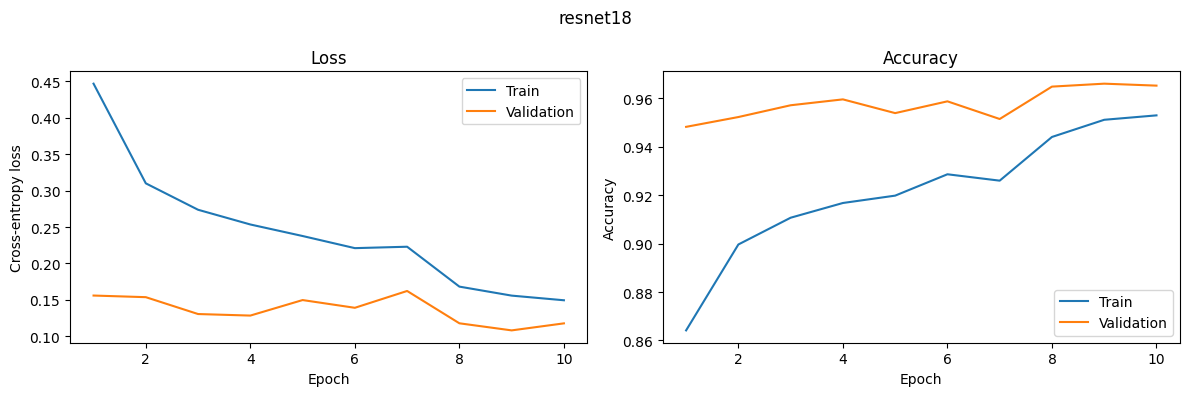

Saved plot: /content/drive/MyDrive/dataset1_outputs/resnet18_training_curves.png
Best validation accuracy: 96.60%
Test accuracy:             97.20%
Predictions saved to:      /content/drive/MyDrive/dataset1_outputs/resnet18_test_predictions.csv

Training resnet34
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 130MB/s]


Epoch 01/10 | train loss=0.4368, acc=0.8590 | val loss=0.1496, acc=0.9518 | 84.9s
Epoch 02/10 | train loss=0.3248, acc=0.8949 | val loss=0.1279, acc=0.9660 | 87.0s
Epoch 03/10 | train loss=0.2849, acc=0.9098 | val loss=0.1324, acc=0.9595 | 87.3s
Epoch 04/10 | train loss=0.2671, acc=0.9147 | val loss=0.1246, acc=0.9591 | 85.9s
Epoch 05/10 | train loss=0.2659, acc=0.9126 | val loss=0.1291, acc=0.9627 | 86.0s
Epoch 06/10 | train loss=0.1861, acc=0.9394 | val loss=0.1054, acc=0.9648 | 86.7s
Epoch 07/10 | train loss=0.1689, acc=0.9459 | val loss=0.1042, acc=0.9672 | 86.6s
Epoch 08/10 | train loss=0.1587, acc=0.9499 | val loss=0.1072, acc=0.9692 | 90.7s
Epoch 09/10 | train loss=0.1609, acc=0.9473 | val loss=0.1020, acc=0.9696 | 89.4s


In [ ]:
results = {}

for model_name in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Training {model_name}")
    print("=" * 70)

    # Build a fresh model for each experiment.
    model = build_model(
        model_name,
        num_classes=num_classes,
        pretrained=PRETRAINED,
    ).to(device)

    # Fine-tune and save the checkpoint with the best validation accuracy.
    model, history, best_val_acc, checkpoint_path = train_model(
        model, model_name
    )

    # Save learning curves and evaluate on the separate test set.
    save_history_plot(history, model_name)
    test_acc, predictions_path = evaluate_test(model, model_name)

    results[model_name] = {
        "best_validation_accuracy": best_val_acc,
        "test_accuracy": test_acc,
        "checkpoint": checkpoint_path,
        "test_predictions": predictions_path,
    }

    print(f"Best validation accuracy: {best_val_acc:.2%}")
    print(f"Test accuracy:             {test_acc:.2%}")
    print(f"Predictions saved to:      {predictions_path}")

# Write one JSON file summarizing all experiments.
results_path = OUTPUT_DIR / "results.json"
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("\nSummary saved to:", results_path)

## 13. Compare the models

The table below compares each model's best validation accuracy and final test accuracy. Test accuracy is meaningful only if the labels represented by the test folders are ground-truth labels.

In [ ]:
summary_df = pd.DataFrame([
    {
        "Model": model_name,
        "Best validation accuracy": result["best_validation_accuracy"],
        "Test accuracy": result["test_accuracy"],
        "Checkpoint": result["checkpoint"],
    }
    for model_name, result in results.items()
]).sort_values("Test accuracy", ascending=False)

display(
    summary_df.style.format({
        "Best validation accuracy": "{:.2%}",
        "Test accuracy": "{:.2%}",
    })
)

## 14. Output files

All outputs are saved in the `OUTPUT_DIR` configured above:

- `resnet18_best.pth`, `resnet34_best.pth`, `vgg19_best.pth` — best model weights.
- `resnet18_training_curves.png`, etc. — training and validation curves.
- `resnet18_test_predictions.csv`, etc. — per-image test predictions.
- `results.json` — metrics and output paths.

### Notes
- The assignment asks for ResNet-18, ResNet-34 and VGG-19, and this notebook runs all three.
- If your test folders are not actually labeled ground truth, do not report the computed test accuracy as a valid benchmark; use the validation accuracy instead.
- Keep the test set separate from model selection. Use validation accuracy to choose checkpoints and test accuracy for the final report.